# News Intelligence Studio — Main Notebook

**Team 116:** Chaman Kumar, Satyam Priyam, Killol

This is the primary notebook entry point for the project. It executes the full project from the bundled raw datasets in `data/raw/`, saves all outputs to `results/`, displays benchmark tables and figures, and lets you enter a custom news article for both analysis and verification.

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

PROJECT_ROOT

PosixPath('<project root>')

## 1. Confirm the bundled raw datasets are present

In [2]:
required_raw_files = [
    PROJECT_ROOT / 'data' / 'raw' / 'kaggle_fake_real' / 'Fake.csv',
    PROJECT_ROOT / 'data' / 'raw' / 'kaggle_fake_real' / 'True.csv',
    PROJECT_ROOT / 'data' / 'raw' / 'fakenewsnet' / 'BuzzFeed_fake_news_content.csv',
    PROJECT_ROOT / 'data' / 'raw' / 'fakenewsnet' / 'BuzzFeed_real_news_content.csv',
    PROJECT_ROOT / 'data' / 'raw' / 'fakenewsnet' / 'PolitiFact_fake_news_content.csv',
    PROJECT_ROOT / 'data' / 'raw' / 'fakenewsnet' / 'PolitiFact_real_news_content.csv',
    PROJECT_ROOT / 'data' / 'raw' / 'news_category' / 'News_Category_Dataset_v3.json',
]

missing = [str(p.relative_to(PROJECT_ROOT)) for p in required_raw_files if not p.exists()]
print('Missing files:' if missing else 'All required raw data files are present.')
missing

All required raw data files are present.


[]

## 2. Full project execution from raw data

This cell calls `demo.run_project(...)`, which is the single standalone project runner. It rebuilds the analyzer from `data/raw/`, refreshes saved outputs in `results/`, and then runs analysis plus verification on one article.

In [3]:
from demo import run_project

project_run = run_project(PROJECT_ROOT, n_topics=12, extra_real_rows=2000, topic_rows=12000)
project_run['rebuild_summary']

{'classifier_rows_used': 41386,
 'extra_real_rows_requested': 2000,
 'topic_rows_used': 11986,
 'n_topics': 12,
 'best_model': 'logistic_regression',
 'best_topic_model': 'nmf',
 'test_f1_weighted': 0.9814818116015193,
 'test_f1_macro': 0.9811944114380504,
 'classifier_selection_reason': 'Highest validation macro F1, with weighted F1 and accuracy as secondary checks. Speed is shown for context but not used as the main criterion.',
 'topic_selection_reason': 'Chosen by the highest topic-model quality score, which prioritizes coherence and topic diversity over runtime.',
 'raw_data_profile': {'kaggle_fake_real': {'rows': 44898,
   'fake_rows': 23481,
   'real_rows': 21417,
   'subjects': 8},
  'fakenewsnet': {'rows': 422,
   'fake_rows': 211,
   'real_rows': 211,
   'source_groups': 4},
  'news_category': {'rows': 209527, 'categories': 42}}}

## 3. Load and display the saved outputs

In [4]:
from src.notebook_runner import load_saved_outputs
from IPython.display import display

outputs = load_saved_outputs(PROJECT_ROOT)
display(outputs['classifier_benchmark'])
display(outputs['topic_benchmark'])
display(outputs['dataset_split'])
display(outputs['source_breakdown'])
outputs['classification_metrics']['test_metrics']

,model_name,accuracy,precision_weighted,recall_weighted,f1_weighted,precision_macro,recall_macro,f1_macro,train_time_sec,predict_time_ms_per_article
0,logistic_regression,0.980992,0.981030,0.980992,0.980978,0.981438,0.979951,0.980660,14.7653,0.2217
1,linear_svc,0.980831,0.980891,0.980831,0.980813,0.981436,0.979643,0.980490,14.5077,0.2122
2,sgd_log_loss,0.980670,0.980707,0.980670,0.980655,0.981110,0.979623,0.980332,15.5822,0.2248
3,multinomial_nb,0.923325,0.924597,0.923325,0.923502,0.921011,0.924932,0.922501,13.5680,0.2119


,model_name,coherence_proxy,topic_diversity,avg_topic_confidence,train_time_sec,coherence_norm,diversity_norm,confidence_norm,quality_score
0,nmf,-3.109140,0.925000,0.045684,1.4283,1.000000,0.6875,0.000000,0.7719
1,kmeans,-3.272267,0.833333,0.086646,1.0558,0.739748,0.0000,0.140078,0.4649
2,lda,-3.735943,0.966667,0.338106,8.1213,0.000000,1.0000,1.000000,0.4000


,split,rows,fake_rows,real_rows
0,train,28970,12673,16297
1,validation,6208,2715,3493
2,test,6208,2716,3492


,dataset_source,rows
0,kaggle_fake_real,39101
1,news_category_real_boost,1996
2,fakenewsnet,289


{'accuracy': 0.9814755154639175,
 'precision_weighted': 0.9815030324807114,
 'recall_weighted': 0.9814755154639175,
 'f1_weighted': 0.9814818116015193,
 'precision_macro': 0.980874997038593,
 'recall_macro': 0.9815292096219931,
 'f1_macro': 0.9811944114380504}

## 4. Display saved result figures

class_balance.png


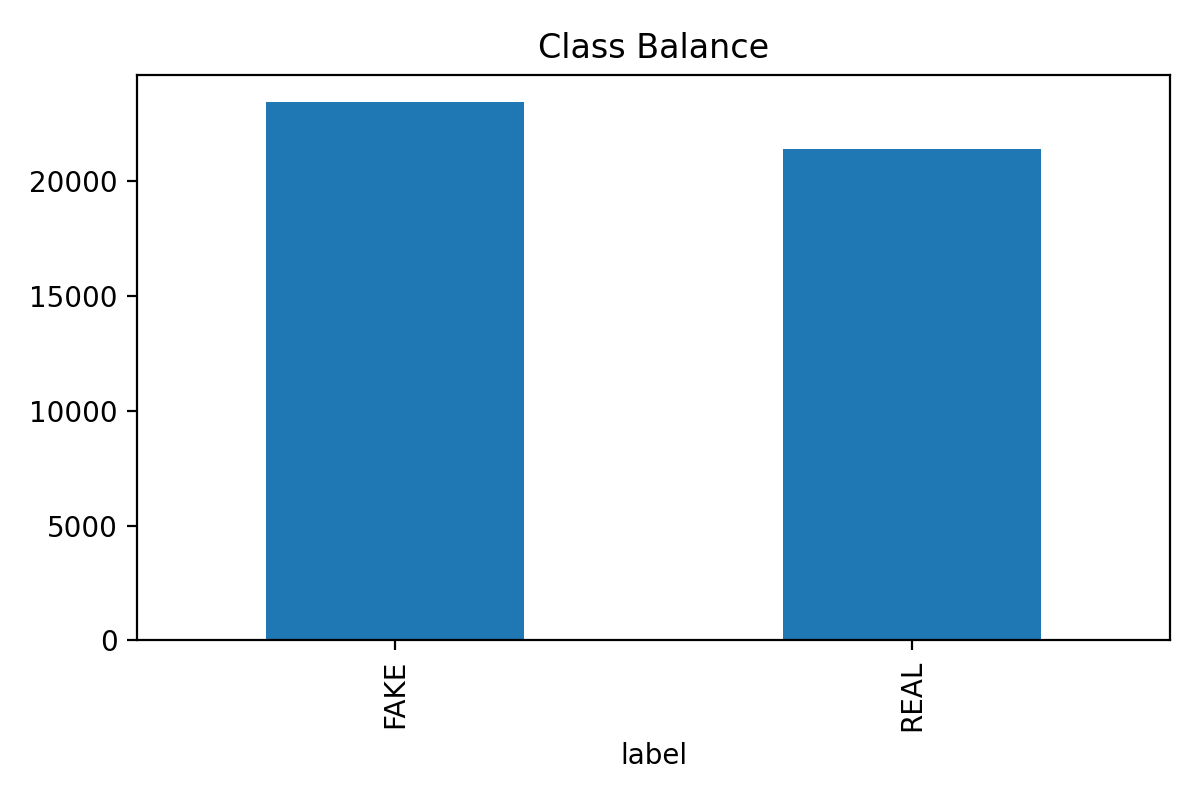

confusion_matrix.png


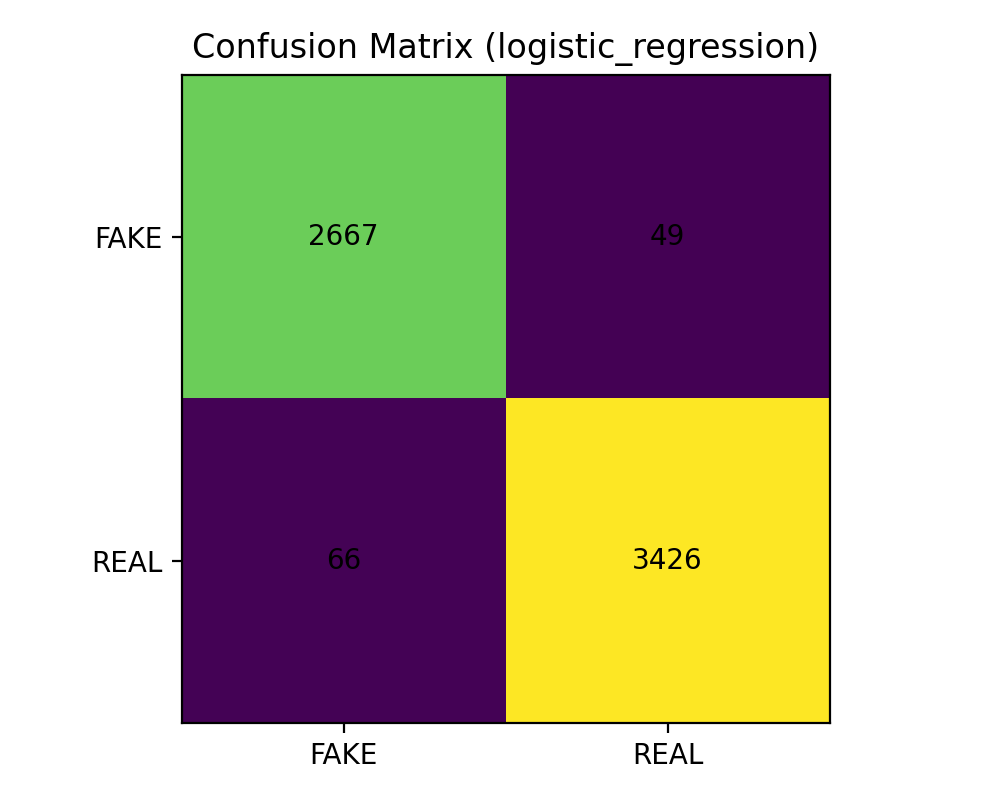

topic_distribution.png


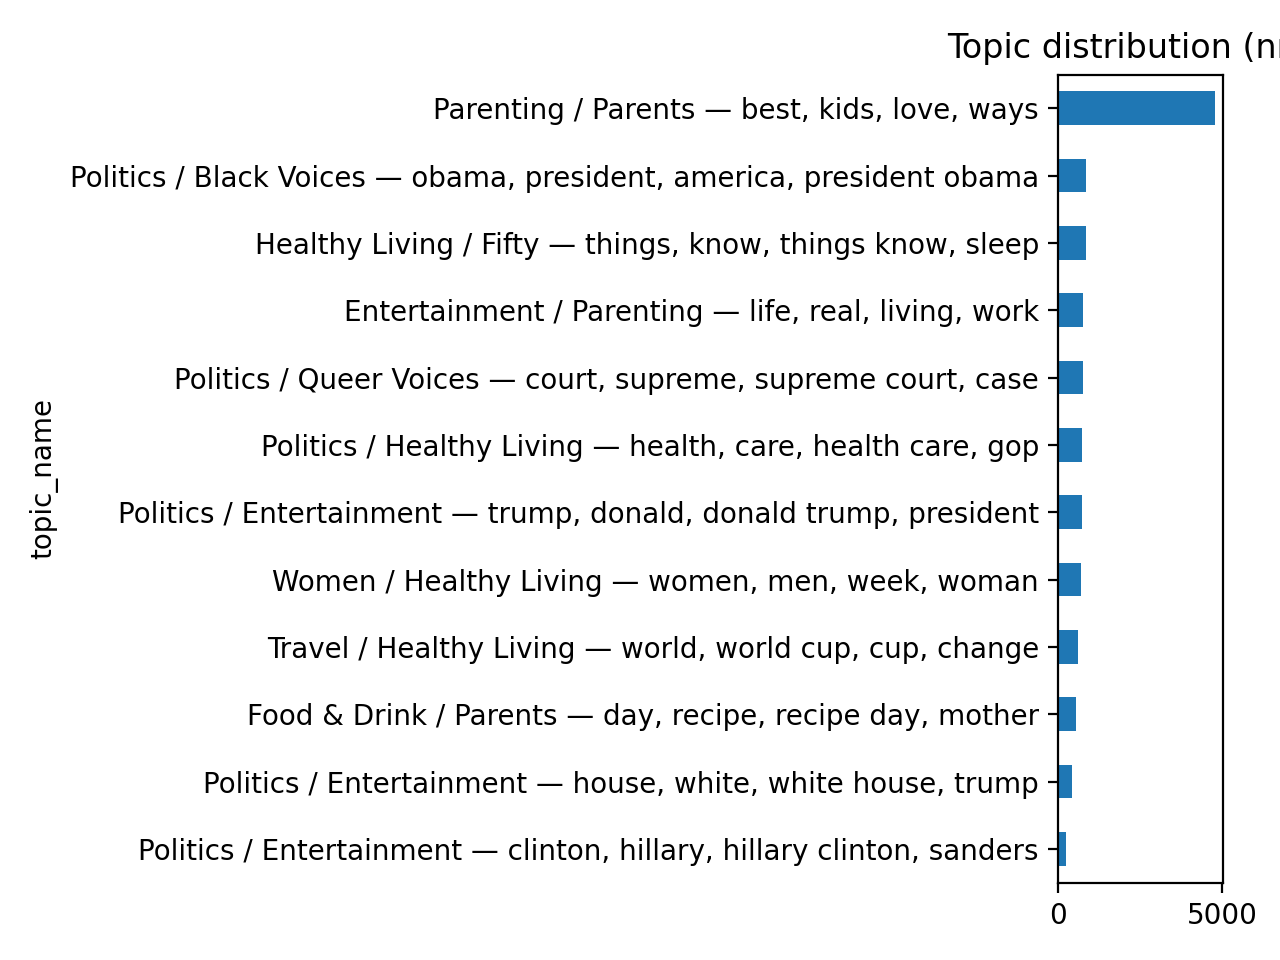

top_subjects.png


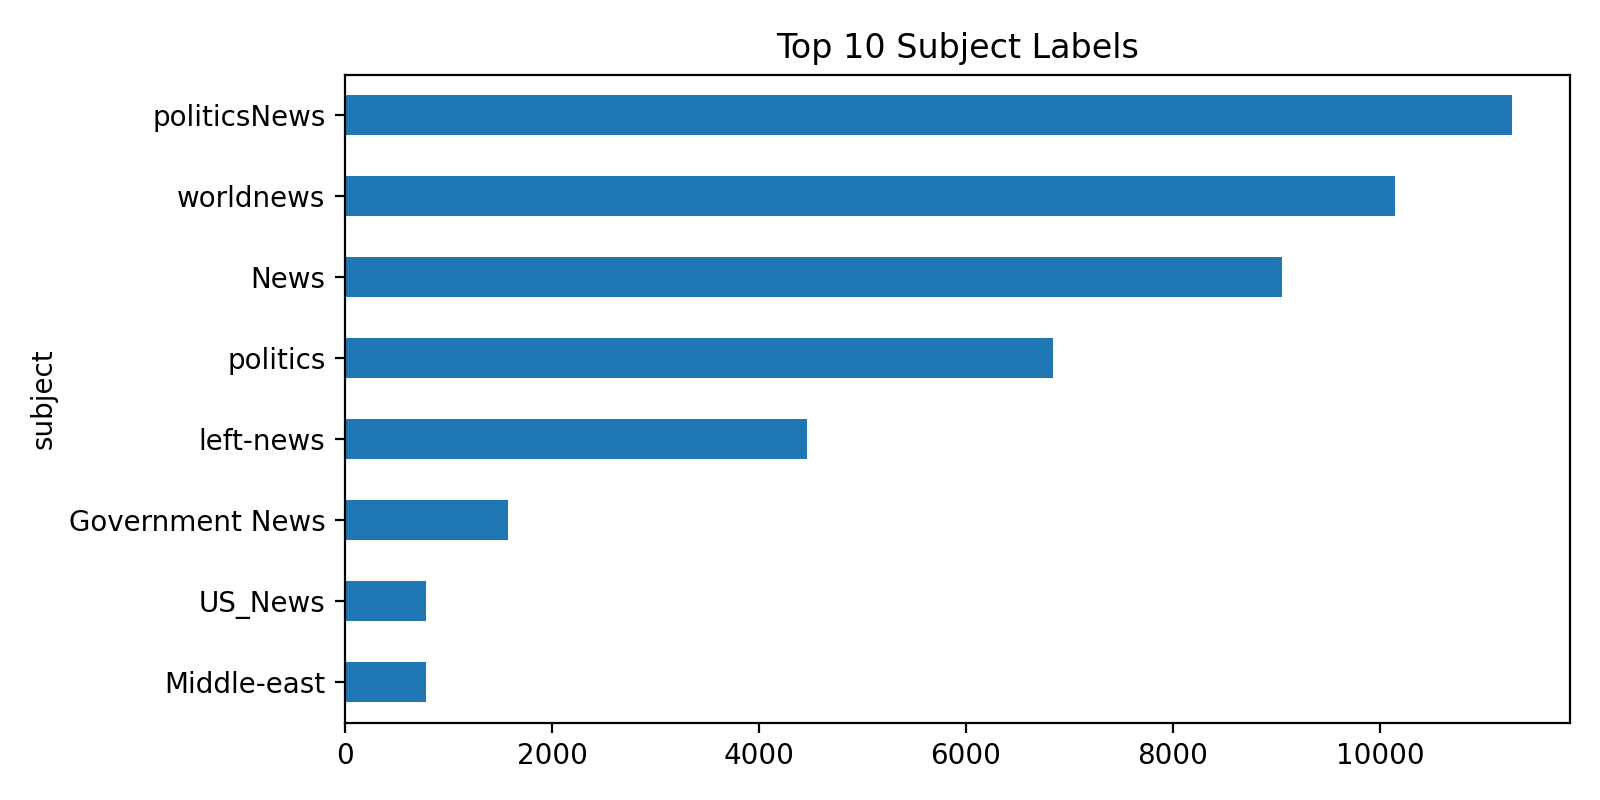

In [5]:
from IPython.display import Image, display

for image_name in ['class_balance.png', 'confusion_matrix.png', 'topic_distribution.png', 'top_subjects.png']:
    image_path = PROJECT_ROOT / 'results' / 'figures' / image_name
    if image_path.exists():
        print(image_name)
        display(Image(filename=str(image_path), width=700))

## 5. Enter your own news article

Edit the headline and article text below, then run the next two code cells. The combined analyzer + verifier output will be shown in the notebook and saved to `results/custom_article_result.json`.

In [6]:
custom_headline = "Iran's ability to threaten Strait of Hormuz is degraded, US says"
custom_article_text = """
IDF says missiles launched from Iran towards Israel. In the last few minutes,
the Israel Defense Forces said it had identified missiles launched towards the country.
Defensive systems were operating to intercept the threat. A precautionary alert was sent
to people in relevant areas.
"""

In [7]:
from src.notebook_runner import analyze_and_save_custom_article
from IPython.display import Markdown, JSON

custom_result = analyze_and_save_custom_article(PROJECT_ROOT, custom_headline, custom_article_text)

print('Analyzer prediction:', custom_result['analysis']['prediction'])
print('Analyzer confidence:', round(custom_result['analysis']['confidence'], 4))
print('Closest theme:', custom_result['analysis']['topic']['topic_name'])
print('Summary:', custom_result['analysis']['summary'])
print('Verification summary:', custom_result['verification']['summary'])

JSON(custom_result)

Analyzer prediction: REAL
Analyzer confidence: 0.8835
Closest theme: Politics / Black Voices — obama, president, america, president obama
Summary: IDF says missiles launched from Iran towards Israel. In the last few minutes, the Israel Defense Forces said it had identified missiles launched towards the country. A precautionary alert was sent to people in relevant areas.
Verification summary: In the last few minutes, the Israel Defense Forces said it had identified missiles launched towards the country. Defensive systems were operating to intercept the threat. Iran's ability to threaten Strait of Hormuz is degraded, US says IDF says missiles launched from Iran towards Israel.


<IPython.core.display.JSON object>

## 6. Optional standalone run

The same full execution path is available from the terminal with:

```bash
python demo.py
```